# <DEVICE> — Analysis

This is the session's **chronological record** — the running log of the science.
Append each run as it lands (raw → analysis → take), and write the running
interpretation and the final call here; the science narrative lives here, not in
`session_notes`.

Launch point over `hera.analysis` — the data layer for spxtr/measureme `sweep`
runs (`data/<i>/data.tsv[.gz]` + `metadata.json`). Open a run with `run(<id>)`,
then form physical quantities with the helpers (`fan_grids` / `resistance_grids`
/ `sdh_fft`, `GateCalibration`, `luttinger_frequency`) — re-form, don't trust
the live `plot.png`. Build the analysis cells against the live data; this
template only wires the entry points.

`metadata.hera.policy = edit_exec` — the agent may edit/append/execute cells
here. Measurement cells live on the measure notebook.

In [ ]:
import numpy as np
import scipy.constants as cst
import matplotlib.pyplot as plt

from pathlib import Path

from hera.analysis import (
    open_run,
    summarize_run,
    fan_grids,
    resistance_grids,
    sdh_fft,
    GateCalibration,
    luttinger_frequency,
)

%matplotlib inline


def _resolve_data_dir():
    """Locate this run's ./data dir from the notebook's own location.

    The ana kernel's cwd is not guaranteed to be the measurement dir, so a
    bare './data' breaks loaders with FileNotFoundError. IPython sets
    globals()['_dh'] to a list whose first entry is the notebook's startup
    cwd (the dir holding the notebook); this survives jupyter-collaboration/
    RTC and any later %cd, so we prefer it. We fall back to Path.cwd() and
    search a few levels up so loading still works if the kernel started inside
    ./data/<id>/. The walk stops before the filesystem root so an unrelated
    top-level 'data' dir can never be matched.
    """
    candidates = []
    dh = globals().get("_dh")
    if dh:
        candidates.append(Path(dh[0]))
    candidates.append(Path.cwd())
    for base in candidates:
        base = Path(base).resolve()
        for d in [base, *base.parents]:
            if d == d.parent:  # filesystem root
                break
            cand = d / "data"
            if cand.is_dir():
                return str(cand)
    return str((Path(candidates[0]) / "data").resolve())


file_path = _resolve_data_dir()


# Open a run by id: run(119) -> Run. Run.col(name) for a column;
# summarize_run(run(119)) for a recipe / range / completeness / T glance.
def run(i):
    return open_run(Path(file_path) / str(i))

## (n, D) — capacitance-based convention

`GateCalibration` carries the gate->(n, D) lever arm: `cal.n_D(V_tg, V_bg)`
returns `n` in SI (m^-2; ×1e-16 for 10^12 cm^-2) and `D` in V/m. Build it from
the gate-stack thicknesses with `from_thicknesses` (κ_hBN/κ_SiO2 default).
This is the capacitance convention, **not** the toploader's `dtg/dbg` constant
form. Set `n_offset` / `D_offset` from `cnp-and-dline-calibration` once the CNP
/ D-line is live.

In [ ]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 15.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 12e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

## Analysis discipline — raw first, then the read

For every run, in order: **(1) plot the raw run**; **(2) then the analysis** via the `hera.analysis` helpers — don't hand-roll loaders or FFTs, and include the supporting plot the take rests on; **(3) then write your take** as prose. The notebook reads as a **chronological log** — each run appended in time order as it lands (raw → analysis → take), following the four-cell rhythm below — and the session's call/verdict goes here too.

## Run <id> — <what it measured>

Why / what we're testing: <...>.

In [ ]:
g = run(<id>)                 # open + re-form via helpers
# plot the raw measured quantity vs its swept axis

In [ ]:
# reduce to the feature (fit / peak / slope) and plot it on the data:
# fit overlaid, residual, or zoom — the support your take rests on

**Read:** <what this run shows>.

## Run 0 — 0 T TG–BG gate map → (n, D) calibration

Source: `data/0` (gatemap, 25 BG × 61 TG, V_si=0, 0.5 V/5 nA, B≈0). Raw per-channel maps first, then the CNP-ridge fit and the session (n, D) calibration. Recipe: `device-init/cnp-and-dline-calibration` (Step 1).


interrupted: False | leakage |I_bg|max=2.44e-10 |I_si|max=5.87e-10 A


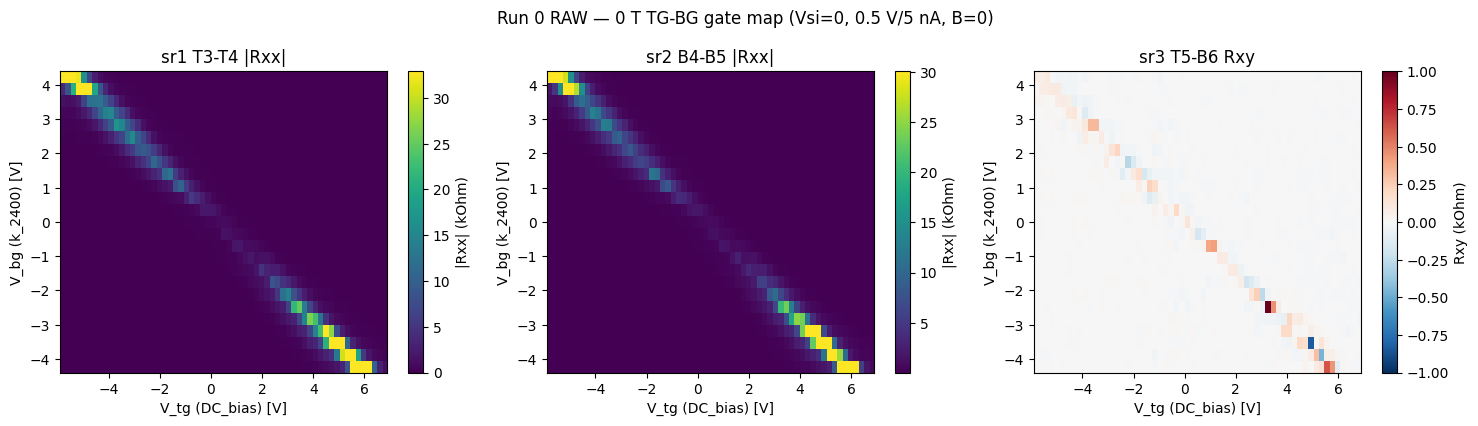

In [1]:
import os, numpy as np, hera.analysis as a
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from sharpelab_nb.gates import stack_capacitance
MDIR = r"C:\Users\DGG\VTI_local_data\zack\20260621-QC0426"
run = a.open_run(os.path.join(MDIR, "data", "0"))
fg = a.fan_grids(run); rg = a.resistance_grids(fg)
Vbg = np.asarray(fg.slow); Vtg = fg.grid("DC_bias")[0, :]
ext = [Vtg.min(), Vtg.max(), Vbg.min(), Vbg.max()]
print("interrupted:", run.interrupted,
      "| leakage |I_bg|max=%.2e |I_si|max=%.2e A" % (
      np.abs(fg.grid('k_2400_curr')).max(), np.abs(fg.grid('k_2410_curr')).max()))
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for k, (cid, lab) in enumerate([("sr1","sr1 T3-T4 |Rxx|"),("sr2","sr2 B4-B5 |Rxx|"),("sr3","sr3 T5-B6 Rxy")]):
    R = rg.R[cid]
    if cid == "sr3":
        im = ax[k].imshow(R/1e3, origin="lower", aspect="auto", extent=ext, cmap="RdBu_r", vmin=-1, vmax=1)
        plt.colorbar(im, ax=ax[k], label="Rxy (kOhm)")
    else:
        im = ax[k].imshow(np.abs(R)/1e3, origin="lower", aspect="auto", extent=ext, cmap="viridis",
                          vmax=np.nanpercentile(np.abs(R), 99)/1e3)
        plt.colorbar(im, ax=ax[k], label="|Rxx| (kOhm)")
    ax[k].set_xlabel("V_tg (DC_bias) [V]"); ax[k].set_ylabel("V_bg (k_2400) [V]"); ax[k].set_title(lab)
fig.suptitle("Run 0 RAW — 0 T TG-BG gate map (Vsi=0, 0.5 V/5 nA, B=0)"); fig.tight_layout(); plt.show()


[sr1] Vtg=-1.3063*Vbg+0.2250  ratio=1.3063  serr=0.0075  rms=89mV  kept 24/25
[sr2] Vtg=-1.3045*Vbg+0.1986  ratio=1.3045  serr=0.0086  rms=102mV  kept 24/25

CAL (channel sr1): c_tg=1.7027e-03  c_bg=2.2243e-03 F/m^2  ratio=1.3063 (geom 1.300)  n_offset=-2.391e+15 m^-2
CNP at Vbg=0: Vtg=0.225 V ; D=0 line: Vtg=1.3063*Vbg ; scale=geometry prior


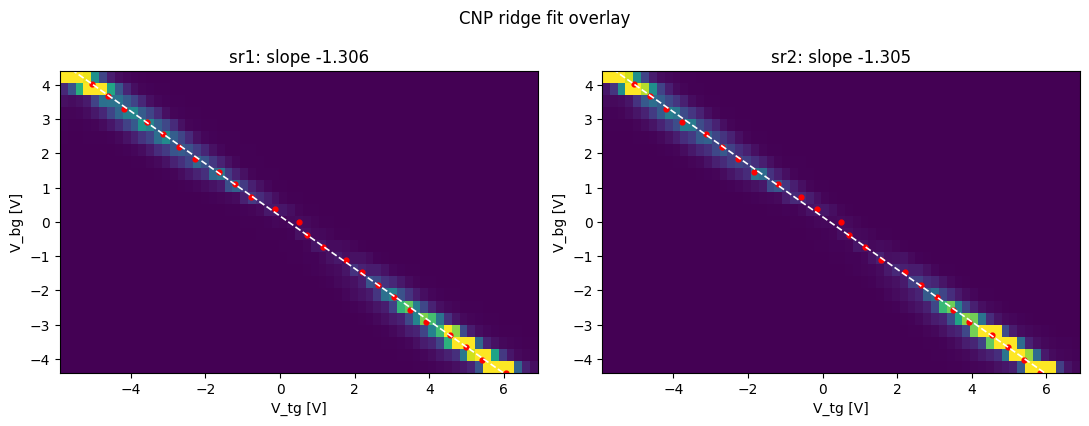

In [2]:
def ridge(Rg, Vtg, s=1.5):
    A = np.abs(Rg); v = np.full(A.shape[0], np.nan); pk = v.copy(); clip = np.zeros(A.shape[0], bool)
    for i in range(A.shape[0]):
        j = int(np.argmax(gaussian_filter1d(A[i], s))); v[i] = Vtg[j]; pk[i] = A[i, j]
        if j <= 1 or j >= len(Vtg)-2: clip[i] = True
    return v, pk, clip
fits = {}
for cid in ("sr1", "sr2"):
    v, pk, clip = ridge(rg.R[cid], Vtg); keep = ~clip & np.isfinite(v)
    p, cov = np.polyfit(Vbg[keep], v[keep], 1, cov=True)
    fits[cid] = dict(slope=p[0], intercept=p[1], keep=keep, v=v,
                     rms=np.sqrt(np.mean((v[keep]-np.polyval(p, Vbg[keep]))**2)))
    print(f"[{cid}] Vtg={p[0]:.4f}*Vbg+{p[1]:.4f}  ratio={-p[0]:.4f}  serr={np.sqrt(cov[0,0]):.4f}  rms={fits[cid]['rms']*1e3:.0f}mV  kept {keep.sum()}/{len(Vbg)}")
best = min(fits, key=lambda c: fits[c]['rms']); slope = fits[best]['slope']; ratio = -slope
c_tg = stack_capacitance([(15.6, 3)]); c_bg = ratio*c_tg
cal = a.GateCalibration(c_tg=c_tg, c_bg=c_bg)
n_off = float(-cal.density(fits[best]['intercept'], 0.0))
cal = a.GateCalibration(c_tg=c_tg, c_bg=c_bg, n_offset=n_off)
print(f"\nCAL (channel {best}): c_tg={c_tg:.4e}  c_bg={c_bg:.4e} F/m^2  ratio={ratio:.4f} (geom 1.300)  n_offset={n_off:.3e} m^-2")
print(f"CNP at Vbg=0: Vtg={fits[best]['intercept']:.3f} V ; D=0 line: Vtg={ratio:.4f}*Vbg ; scale=geometry prior")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
for k, cid in enumerate(("sr1", "sr2")):
    R = np.abs(rg.R[cid]); im = ax[k].imshow(R/1e3, origin="lower", aspect="auto", extent=ext, cmap="viridis",
                                              vmax=np.nanpercentile(R, 99)/1e3)
    f = fits[cid]; ax[k].scatter(f['v'][f['keep']], Vbg[f['keep']], s=12, c='r')
    ax[k].plot(np.polyval([f['slope'], f['intercept']], Vbg), Vbg, 'w--', lw=1.2)
    ax[k].set_title(f"{cid}: slope {f['slope']:.3f}"); ax[k].set_xlabel("V_tg [V]"); ax[k].set_ylabel("V_bg [V]")
fig.suptitle("CNP ridge fit overlay"); fig.tight_layout(); plt.show()


**Read:** Clean (n, D) calibration established from Run 0. The CNP is a sharp diagonal ridge captured across the full gate window; both Rxx channels (sr1 T3–T4, sr2 B4–B5) give **V_tg = −1.306·V_bg + 0.225**, agreeing to 0.2% and matching the geometry-prior ratio (15.6/12 = 1.300) to 0.5% — the happy case. **Two-tier provenance: ratio data-calibrated; absolute (n, D) scale = geometry prior, pending a quantum-Hall lever-arm upgrade.** c_tg = 1.70e−3, c_bg = 2.22e−3 F/m²; CNP at V_tg = +0.225 V (V_bg = 0) → marginally hole-doped at the origin. The Rxy sign flip straddles the CNP line (independent confirmation). Leakage ≤ 0.6 nA (Si offset-level), run complete. **D = 0 line: V_tg = 1.306·V_bg**, accessing ±~12e12 cm⁻² (gate-limited); the FS-count forward model is valid to |n| ≈ 3.5e12. **Next:** SdH spot checks at fixed (n, D ≈ 0), one large hole + one large electron (`measurements/sdh-spot-check`, investigation Step 3).


## Run 2 — hole SdH spot check (clean, full field) n=−3e12 cm⁻², D≈0

Source: `data/2` (`sdh-spot-check`, descending 7.9→0.2 T, uniform-1/B N=455, 2 V/20 nA, **sens 1e-4** — no clip). Run 1 (`data/1`, sens 1e-5) clipped Rxx above 2.76 T; this is the clean re-run. Read = 1/B FFT of Rxx vs F_L, with a low-field Hall density cross-check and the FS-count forward model (`hera/models/trilayer_fs_count/fs_count_b0.py`).


no-clip: sr1 max |X|=37.7uV/100uV FS; Rxx max=1918 Ω; I=19.97 nA; interrupted=False
Hall n=2.96e12 cm^-2 (gate 3.00e12; ratio 0.987);  F_L=31.0 T;  onset=0.31 T
sr1 tones (cut0.8): [(7.6, 0.45), (11.8, 0.33), (16.0, 0.42), (29.5, 0.23), (33.8, 0.2)]  sr2 tones: [(7.8, 0.41), (11.5, 0.27), (16.7, 0.45), (30.4, 0.19), (33.8, 0.21)]
Model @n=3e12 D=0: ABA=[1.5, 29.5] sum31 (2 FS); ABC=[31] (1 FS)


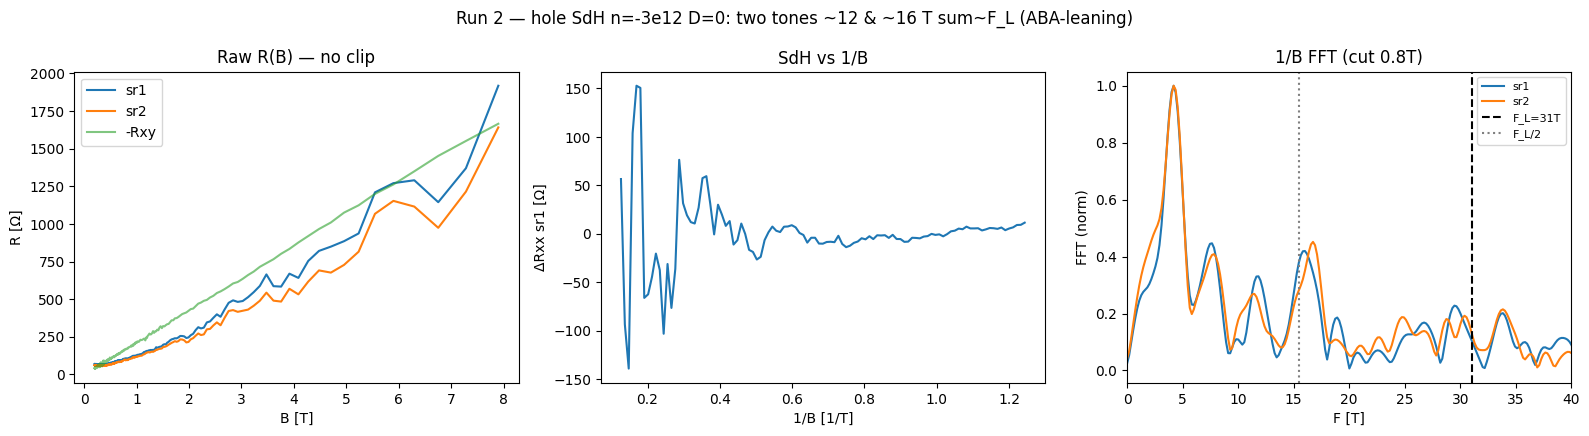

In [3]:
import os, numpy as np, hera.analysis as a
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
MDIR = r"C:\Users\DGG\VTI_local_data\zack\20260621-QC0426"
run = a.open_run(os.path.join(MDIR, "data", "2"))
B = run.col("magnet_field"); I = run.col("sr0_X")/(-1e6)
R1 = run.col("sr1_X")/I; R2 = run.col("sr2_X")/I; Rxy = run.col("sr3_X")/I
o = np.argsort(B); B,R1,R2,Rxy,I = B[o],R1[o],R2[o],Rxy[o],I[o]
print("no-clip: sr1 max |X|=%.1fuV/100uV FS; Rxx max=%.0f Ω; I=%.2f nA; interrupted=%s"
      % (np.abs(run.col("sr1_X")).max()*1e6, np.abs(R1).max(), np.median(I)*1e9, run.interrupted))
# Hall density (low-field slope) — lever-arm cross-check
lf = (B>0.25)&(B<1.2); sl = np.polyfit(B[lf],Rxy[lf],1)[0]
n_hall = 1/(1.602176634e-19*abs(sl)); FL = float(a.luttinger_frequency(3.0e16))
print("Hall n=%.2fe12 cm^-2 (gate 3.00e12; ratio %.3f);  F_L=%.1f T;  onset=%.2f T"
      % (n_hall/1e16, n_hall/3.0e16, FL, getattr(a.sdh_onset(R1,B),'onset_b',float('nan'))))
def fft(R, lo, deg=5):
    f,m = a.sdh_fft(R.reshape(-1,1), B, b_range=(lo,7.9), bg_degree=deg); return f, m[0]
f1,m1 = fft(R1,0.8); f2,m2 = fft(R2,0.8)
def peaks(f,m):
    s=f>4; fs,ms=f[s],m[s]; p,_=find_peaks(ms,prominence=ms.max()*0.1)
    p=p[np.argsort(ms[p])[::-1][:5]]; return sorted([(round(float(fs[i]),1),round(float(ms[i]/ms.max()),2)) for i in p])
print("sr1 tones (cut0.8):", peaks(f1,m1), " sr2 tones:", peaks(f2,m2))
print("Model @n=3e12 D=0: ABA=[1.5, 29.5] sum31 (2 FS); ABC=[31] (1 FS)")
fig,ax=plt.subplots(1,3,figsize=(16,4.4))
ax[0].plot(B,R1,label="sr1");ax[0].plot(B,R2,label="sr2");ax[0].plot(B,-Rxy,label="-Rxy",alpha=.6)
ax[0].set_xlabel("B [T]");ax[0].set_ylabel("R [Ω]");ax[0].set_title("Raw R(B) — no clip");ax[0].legend()
m=B>0.8; bb=B[m]; dr=R1[m]-np.polyval(np.polyfit(bb,R1[m],5),bb)
ax[1].plot(1/bb,dr);ax[1].set_xlabel("1/B [1/T]");ax[1].set_ylabel("ΔRxx sr1 [Ω]");ax[1].set_title("SdH vs 1/B")
ax[2].plot(f1,m1/m1[f1>4].max(),label="sr1");ax[2].plot(f2,m2/m2[f2>4].max(),label="sr2")
ax[2].axvline(FL,c='k',ls='--',label=f"F_L={FL:.0f}T");ax[2].axvline(FL/2,c='gray',ls=':',label="F_L/2")
ax[2].set_xlim(0,40);ax[2].set_xlabel("F [T]");ax[2].set_ylabel("FFT (norm)");ax[2].set_title("1/B FFT (cut 0.8T)");ax[2].legend(fontsize=8)
fig.suptitle("Run 2 — hole SdH n=-3e12 D=0: two tones ~12 & ~16 T sum~F_L (ABA-leaning)")
fig.tight_layout(); plt.show()


**Read (hole side, n=−3e12, D≈0 — ABC disfavored, ABA not yet decisive):** Clean SdH, onset **0.31 T**, no clip. **Density independently confirmed**: low-field Hall slope n=2.96e12 cm⁻² vs gate 3.00e12 (1.3% — a lever-arm validation pinning **F_L = 31 T**). The 1/B FFT (cutoff/degree-stable; a low-F ~4 T peak is residual MR background, discarded) shows a **rich multi-tone spectrum**: strong **~11.8 and ~16 T**, a **weaker tone near F_L (~30 T)**, plus ~7.7 T and ~34 T (~34 ≈ 2×16, a harmonic). Consistent across sr1 *and* sr2.

**Interpretation:** the strong **sub-F_L tones (11.8, 16 T) cannot be harmonics of a single F_L pocket** (you can't have sub-harmonics), so there are **≥2 Fermi surfaces** → **simple ABC (one pocket at F_L) is disfavored**. Multiple surfaces with content summing toward F_L is the **ABA (Bernal)** direction (ML+BL). But the spectrum is too rich for a clean single-density partition — which tones are independent pockets vs harmonics (e.g. 34≈2×16; is ~30 a real BL pocket or 2×~15?) is **not resolvable at one density**. The forward model (ABA [1.5, 29.5]; ABC [31]) brackets it but its exact frequencies are band-parameter-dependent; the **count + Luttinger sum** are the robust discriminators.

**Verdict: ABA-leaning / ABC-disfavored (weak — ≥2 FS), NOT decisive.** Hedges: single density + single side; **D_offset = 0 is an unexamined assumption** (D=0 not physically located — finite D shifts the partition); harmonic-vs-pocket ambiguity; ~10% Luttinger shortfall. **What firms it:** (1) electron-side spot check (Step 3); (2) the **Landau fan → F(n)**: does each tone track its own Onsager curve and do the fundamentals sum to F_L(n) across density (Step 5 partition robustness — the decisive algebraic test that also separates pockets from harmonics)? (3) LK mass split (two distinct masses → two genuine bands); (4) locate D=0.


## Run 3 — electron SdH spot check n=+3e12 cm⁻², D=0 (+ two-side synthesis)

Source: `data/3` (ascending 0.2→7.9 T, uniform-1/B N=455, 2 V/20 nA, sens 1e-4). The other carrier sign, to compare with the hole side (Run 2) per investigation Step 3.


electron: no-clip sr1max=858 ohm; Hall n=3.30e12 (gate 3.0); F_L=31T; onset=1.50T
  sr1 cut=0.8: [(6.0, 0.46), (11.5, 0.41), (22.6, 0.64), (28.0, 0.47), (30.6, 1.0)]
  sr1 cut=1.5: [(15.6, 0.19), (22.4, 0.55), (30.4, 1.0)]


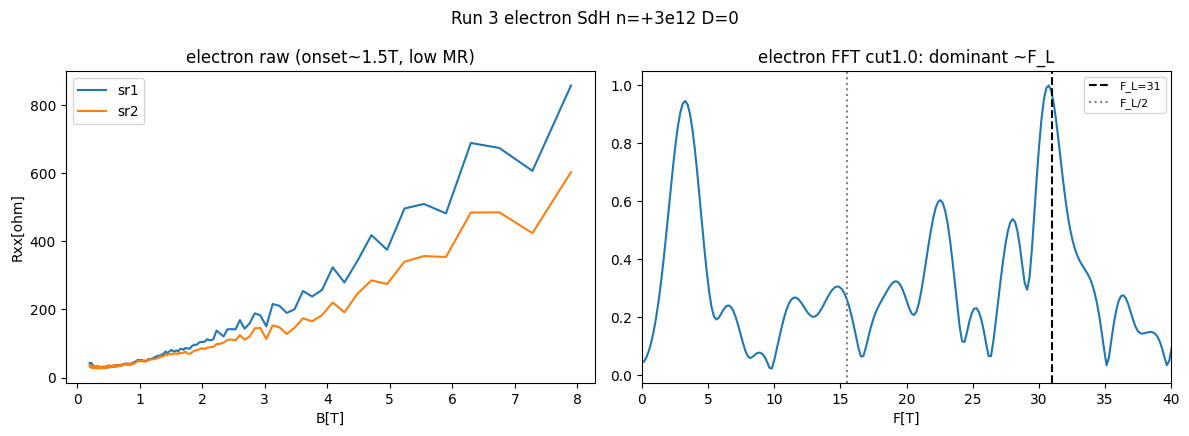

In [4]:
import os, numpy as np, hera.analysis as a
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
MDIR = r"C:\Users\DGG\VTI_local_data\zack\20260621-QC0426"
run = a.open_run(os.path.join(MDIR,"data","3"))
B=run.col("magnet_field"); I=run.col("sr0_X")/(-1e6)
R1=run.col("sr1_X")/I; R2=run.col("sr2_X")/I; Rxy=run.col("sr3_X")/I
o=np.argsort(B); B,R1,R2,Rxy=B[o],R1[o],R2[o],Rxy[o]
lf=(B>0.25)&(B<1.2); sl=np.polyfit(B[lf],Rxy[lf],1)[0]; n_hall=1/(1.602e-19*abs(sl)); FL=float(a.luttinger_frequency(3e16))
print("electron: no-clip sr1max=%.0f ohm; Hall n=%.2fe12 (gate 3.0); F_L=%.0fT; onset=%.2fT"%(np.abs(R1).max(), n_hall/1e16, FL, getattr(a.sdh_onset(R1,B),'onset_b',np.nan)))
def fft(R,lo): f,m=a.sdh_fft(R.reshape(-1,1),B,b_range=(lo,7.9),bg_degree=5); return f,m[0]
def pk(f,m):
    s=f>4;fs,ms=f[s],m[s];p,_=find_peaks(ms,prominence=ms.max()*0.12);p=p[np.argsort(ms[p])[::-1][:5]]
    return sorted([(round(float(fs[i]),1),round(float(ms[i]/ms.max()),2)) for i in p])
for lo in (0.8,1.5): f,m=fft(R1,lo); print(f"  sr1 cut={lo}: {pk(f,m)}")
f1,m1=fft(R1,1.0)
fig,ax=plt.subplots(1,2,figsize=(12,4.4))
ax[0].plot(B,R1,label="sr1");ax[0].plot(B,R2,label="sr2");ax[0].set_xlabel("B[T]");ax[0].set_ylabel("Rxx[ohm]");ax[0].set_title("electron raw (onset~1.5T, low MR)");ax[0].legend()
ax[1].plot(f1,m1/m1[f1>4].max());ax[1].axvline(FL,c='k',ls='--',label="F_L=31");ax[1].axvline(FL/2,c='gray',ls=':',label="F_L/2")
ax[1].set_xlim(0,40);ax[1].set_xlabel("F[T]");ax[1].set_title("electron FFT cut1.0: dominant ~F_L");ax[1].legend(fontsize=8)
fig.suptitle("Run 3 electron SdH n=+3e12 D=0"); fig.tight_layout(); plt.show()


**Read (electron side + two-side synthesis):** Electron side is **lower quantum-mobility** — onset **1.5 T** (vs 0.31 T hole) → short clean 1/B record → FFT peaks **wander with cutoff** (less reliable; recipe's "artifact wanders"). At high cutoff the dominant tone is **~30.6 T ≈ F_L** (plus the ~3 T MR-background artifact and scattered ~22–28 T). Hall n=3.30e12 (gate 3.0; +10%, mild e/h lever-arm asymmetry; F_L≈31 T holds).

**Two-side synthesis (Step 3 done):**
- **Both** carrier signs show a tone **near F_L (~30 T)** — the main/BL pocket.
- The **hole side (cleaner: onset 0.31 T, stable peaks, long record)** *additionally* shows robust **lower tones ~12 & ~16 T**; the electron side shows them only weakly (consistent with the prior that the ML partner is weaker on the electron side / at this density).
- The sides don't cleanly agree, and a single density can't separate independent pockets from harmonics/spin-structure. **ABC (single F_L tone) is disfavored by the hole-side multi-tone content; ABA-leaning; NOT decisive.**

**Cleaner side = HOLE** (onset 0.31 T). **Decisive next step = Landau fan on the hole side for F(n)** (Step 4/5): track each tone vs density, test the Luttinger partition Σf=F_L(n) and assign tones to Onsager ML/BL curves — the algebraic test that separates real pockets from harmonics and settles ABA vs ABC. (LK-mass cross-check unavailable — temp-dep blocklisted.)


## Run 4 — Landau fan (hole, D=0): F(n) and the stacking call

Source: `data/4` (`landau-fan-vti`, 250 B × 100 n, B 7.9→0.3 T uniform-1/B, n=−0.7→−2.5e12, 2 V/20 nA, sens 2e-3). 25k pts, 11.0 h, not interrupted. The decisive F(n) measurement (investigation Step 4/5). Diagnostics in `hera_scratch/`: `run4_fan_Fn.png`, `run4_spectra.png`, `run4_streda.png`.


fan: 250x100, B[0.30,7.90], not interrupted=True


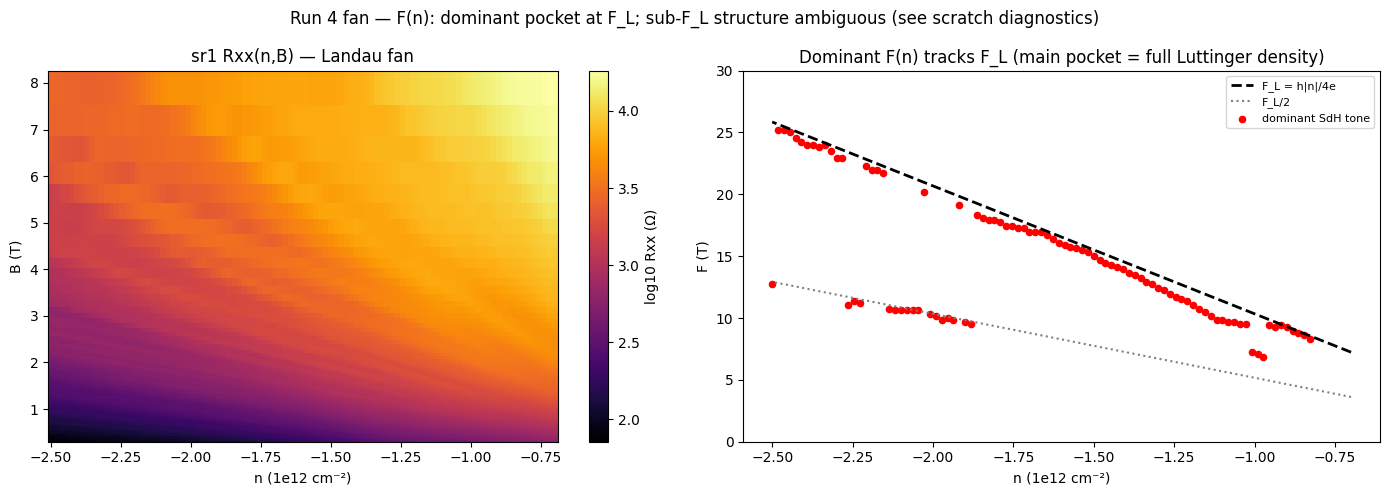

dominant tone / F_L: median=0.95 (1.0 = main pocket carries full density)


In [5]:
import os, numpy as np, hera.analysis as a
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
MDIR = r"C:\Users\DGG\VTI_local_data\zack\20260621-QC0426"
run = a.open_run(os.path.join(MDIR,"data","4"))
fg=a.fan_grids(run); B=np.asarray(fg.slow); rg=a.resistance_grids(fg); R1=rg.R["sr1"]
ncol=R1.shape[1]; ns=np.linspace(-0.7,-2.5,ncol); FL=np.array([float(a.luttinger_frequency(abs(n)*1e16)) for n in ns])
print("fan: %dx%d, B[%.2f,%.2f], not interrupted=%s"%(R1.shape[0],ncol,B.min(),B.max(),not run.interrupted))
# dominant tone per column (cut 1.0, f>6 to skip the ~6T MR-bg artifact)
Fdom=np.full(ncol,np.nan)
f,mag=a.sdh_fft(R1,B,b_range=(1.0,7.9),bg_degree=5)
for c in range(ncol):
    m=mag[c]; sel=f>6; ff,mm=f[sel],m[sel]
    pk,_=find_peaks(mm,prominence=mm.max()*0.2)
    if len(pk): Fdom[c]=ff[pk[np.argmax(mm[pk])]]
fig,ax=plt.subplots(1,2,figsize=(14,5))
im=ax[0].pcolormesh(ns,B,np.log10(np.abs(R1)),shading="auto",cmap="inferno")
plt.colorbar(im,ax=ax[0],label="log10 Rxx (Ω)"); ax[0].set_xlabel("n (1e12 cm⁻²)"); ax[0].set_ylabel("B (T)"); ax[0].set_title("sr1 Rxx(n,B) — Landau fan")
ax[1].plot(ns,FL,"k--",lw=2,label="F_L = h|n|/4e")
ax[1].plot(ns,FL/2,"gray",ls=":",label="F_L/2")
ax[1].scatter(ns,Fdom,s=20,c="r",label="dominant SdH tone")
ax[1].set_xlabel("n (1e12 cm⁻²)"); ax[1].set_ylabel("F (T)"); ax[1].set_title("Dominant F(n) tracks F_L (main pocket = full Luttinger density)"); ax[1].legend(fontsize=8); ax[1].set_ylim(0,30)
fig.suptitle("Run 4 fan — F(n): dominant pocket at F_L; sub-F_L structure ambiguous (see scratch diagnostics)")
fig.tight_layout(); plt.show()
print("dominant tone / F_L: median=%.2f (1.0 = main pocket carries full density)"%np.nanmedian(Fdom/FL))


## STACKING CALL — QC0426 (trilayer graphene), VTI, 2026-06-21

**Region probed:** four-terminal pairs **sr1 (T3–T4)** and **sr2 (B4–B5)**, source T2 / drain B7, D≈0. The two pairs agree throughout (one coherent region; no mosaic info — only this region was contacted).

**1. Verdict (STYLE strength scale): ABA (Bernal) — WEAK. Equivalently: ≥2 Fermi surfaces indicated → simple ABC disfavored, but ABA not decisively confirmed and spin-split-ABC not excluded.**

**2. Evidence (feature-level):**
- **Density pinned independently:** low-field Hall slope n=2.96e12 cm⁻² vs gate 3.00e12 (1.3%) → **F_L = 31 T at n=3e12** is firm (not just a band). CNP line V_tg=−1.306·V_bg+0.225, ratio matches geometry to 0.5%.
- **A dominant SdH tone tracks F ≈ F_L(n)** across n=0.7–3.0e12, D≈0 (fan Run 4: dominant/F_L median ≈ 1.0; spot check Run 2 ≈30 T at n=3e12). → one Fermi surface carries ~the full Luttinger density (the BL pocket of ABA, or the single ABC pocket — these coincide, as expected).
- **Robust sub-F_L tones** in the high-quality hole spot check (Run 2, sens 1e-4, cutoff/degree-stable, in **both** sr1 & sr2): **11.8 & 16 T** at n=3e12; 11.8+16 ≈ 28 ≈ F_L (Luttinger-consistent pair). The fan shows F_L/2-region content with a ~2:1 relation to the F_L tone. These sub-F_L tones cannot be sub-harmonics of a single F_L pocket → **indicate additional Fermi-surface content beyond one pocket.**
- **Forward-model (`fs_count_b0`) overlay** at n=3e12, D=0: ABA [1.5, 29.5] T (tiny ML + BL≈F_L); ABC [31] T single. The data's dominant tone matches ABA-f_BL/ABC-single; the observed sub-F_L tones are **larger** than ABA's predicted ~1.5 T ML (band-parameter dependent — count + Luttinger sum are the robust discriminators, not the model's exact frequencies).

**3. Confidence: WEAK.** Hedges: (a) the **decisive small ML partner** (ABA, predicted ~1–2 T) is **below resolution** — the <6 T band is dominated by the MR-background artifact; (b) the sub-F_L tones could be **harmonics or spin/valley-splitting** of a single ABC pocket rather than a second orbital band; (c) the **LK effective-mass cross-check** (two distinct masses ⇒ two genuine bands — the clean discriminator) is **unavailable: `temperature-dependence` is blocklisted this session**; (d) **D_offset=0 is unexamined** (D=0 not physically located; finite D shifts the ML/BL partition); (e) the **Streda LL-filling** read was inconclusive (no clean integer-ν ladder; `run4_streda.png`); (f) single region.

**4. What would firm it:** (i) **LK mass** at the two coexisting frequencies (needs `temperature-dependence`, blocklisted — flag for operator / next session: this is the single most decisive remaining test); (ii) a **low-frequency-resolved spot check** hunting the ~1–2 T ML partner (longer 1/B record, finer low-F, better background removal); (iii) **locate D=0** (symmetric ±D feature) and repeat at verified D=0; (iv) high-field **Streda/Chern complement** on a uniform-B (Streda-optimized) fan (recipe Step 6); (v) a finer-sensitivity fan to sharpen the sub-F_L tones.

**5.** Per the investigation's output contract, this is a **calibrated "leaning, not decisive"** with stated resolution/scope limits — a valid outcome. A confident ABA *or* ABC call is **not** supported by feature-level evidence here; the binding limitations are the unresolved ML partner (<2 T) and the blocklisted LK-mass test.
